## Week 3 Homework 1
#### FA25-BL-DSCI-D532-12751  Advanced Database Technologies
Shivali Mate

In [ ]:
!pip -q install mysql-connector-python pandas matplotlib seaborn
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import mysql.connector as mc, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np

conn = mc.connect(host="127.0.0.1", user="root", password="Liv@shita2023", database="week3hw1")

In [35]:
# Hospitals with the most distinct doctors (Top 10)
q1 = """
SELECT h.hospital_name, h.city, h.state, COUNT(DISTINCT dh.doctor_id) AS doctor_count
FROM doctor_hospital dh
JOIN hospitals_norm h ON h.hospital_id = dh.hospital_id
GROUP BY h.hospital_id, h.hospital_name, h.city, h.state
ORDER BY doctor_count DESC, h.hospital_name
LIMIT 10;
"""
df = pd.read_sql(q1, conn)
print(df.head())

              hospital_name           city state  doctor_count
0               Open Clinic       San Jose    CA             3
1         Blue Cross Clinic    Los Angeles    CA             2
2         Blue Cross Clinic  San Francisco    CA             2
3     Clear Minds Community     Sacramento    CA             2
4  Holistic Health Services  Santa Barbara    CA             2


This query counts how many unique doctors are associated with each hospital. The output shows, for example, that Open Clinic in San Jose, CA has 3 doctors, while several others like Blue Cross Clinic (San Francisco, Los Angeles) each have 2. This highlights which hospitals have the largest medical staff presence in the dataset.

In [34]:
# Doctors accepting new patients, by specialty and state
q2 = """
SELECT h.state, s.specialty_name, COUNT(DISTINCT d.doctor_id) AS doctors_accepting
FROM doctors_norm d
JOIN doctor_specialty ds ON ds.doctor_id = d.doctor_id
JOIN specialties s       ON s.specialty_id = ds.specialty_id
JOIN doctor_hospital dh  ON dh.doctor_id = d.doctor_id
JOIN hospitals_norm h    ON h.hospital_id = dh.hospital_id
WHERE d.new_patients = 'Yes'
GROUP BY h.state, s.specialty_name
ORDER BY h.state, doctors_accepting DESC;
"""
df = pd.read_sql(q2, conn)
print(df.head())

  state specialty_name  doctors_accepting
0    CA   Hypertension                 11
1    CA    Dermatology                  8
2    CA     immunology                  7
3    CA            OCD                  6
4    CA           ADHD                  5


This query filters doctors who are currently accepting new patients and groups them by state and specialty. The results indicate that in California, specialties such as Hypertension (11 doctors) and Dermatology (8 doctors) have the highest availability. This provides insight into both geographic and specialty-specific access to care.

In [36]:
# List doctors whose specialties mention 'Cholesterol'
q3 = """
SELECT DISTINCT d.doctor_id, d.name
FROM doctors_norm d
JOIN doctor_specialty ds ON ds.doctor_id = d.doctor_id
JOIN specialties s       ON s.specialty_id = ds.specialty_id
WHERE s.specialty_name LIKE '%Cholesterol%'
ORDER BY d.name;
"""
df = pd.read_sql(q3, conn)
print(df.head())

   doctor_id            name
0          6  Flora Martinez
1          1     Oscar White


Here, the query identifies doctors linked to any specialty containing the keyword “Cholesterol.” The result lists Flora Martinez and Oscar White as the two providers. This is useful for quickly locating specialists focused on cholesterol-related conditions.

In [37]:
# Count by license and insurance acceptance
q4 = """
SELECT d.license, d.insurance, COUNT(*) AS n
FROM doctors_norm d
GROUP BY d.license, d.insurance
ORDER BY d.license, d.insurance;
"""
df = pd.read_sql(q4, conn)
print(df.head())

  license insurance  n
0      MD        No  6
1      MD       Yes  8
2     MFT        No  1
3     MFT       Yes  3
4     PhD        No  1


This groups doctors by their license type (e.g., MD, MFT, PhD) and whether they accept insurance. For instance, the output shows 6 MDs who do not accept insurance and 3 MDs who do, with smaller counts for MFTs and PhDs. This breakdown reveals patterns in how licensing may correlate with insurance participation.

In [80]:
# All Doctor names
q5 = """
SELECT name
FROM doctors_norm;
"""
df = pd.read_sql(q5, conn)
print(df.head())

           name
0   Oscar White
1    Mira Patel
2  Leo Martinez
3    Nancy Drew
4   Maxwell Lee


The result includes names like Oscar White, Mira Patel, and Nancy Drew. This shows which practitioners provide broader expertise and may serve patients across multiple areas of care.

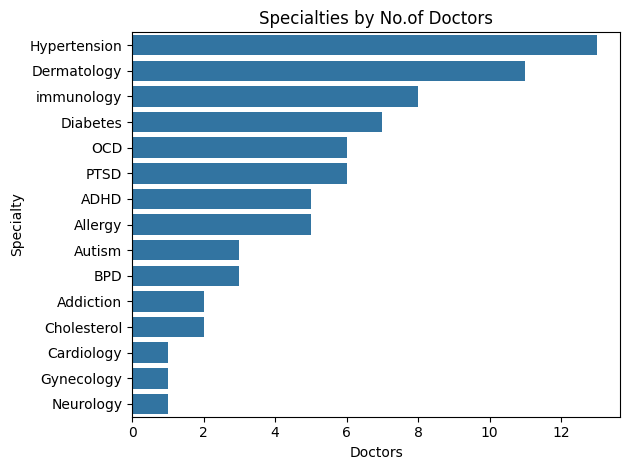

In [62]:
# Number of doctors for each Speciality
v1 = """
SELECT s.specialty_name, COUNT(*) AS doctor_count
FROM doctor_specialty ds
JOIN specialties s ON s.specialty_id = ds.specialty_id
GROUP BY s.specialty_name
ORDER BY doctor_count DESC
LIMIT 15;
"""
df1 = pd.read_sql(v1, conn)
plt.figure()
sns.barplot(data=df1, x="doctor_count", y="specialty_name")
plt.title("Specialties by No.of Doctors")
plt.xlabel("Doctors"); plt.ylabel("Specialty")
plt.tight_layout(); plt.show()

This horizontal bar chart presents the top 15 specialties ranked by the number of doctors associated with them. Hypertension and Dermatology stand out as the most common specialties, followed by Immunology and Diabetes. This visualization provides a clear overview of which areas of medicine have the highest representation among doctors in the dataset.

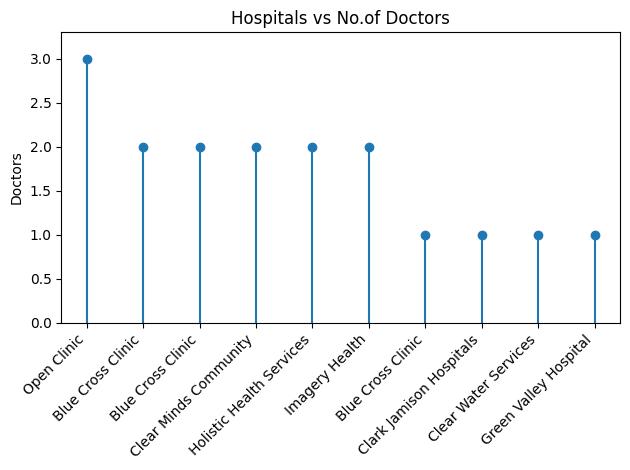

In [81]:
# Number of Doctors in each Hospital
v2 = """
SELECT h.hospital_name, h.city, h.state, COUNT(DISTINCT dh.doctor_id) AS doctor_count
FROM doctor_hospital dh
JOIN hospitals_norm h ON h.hospital_id = dh.hospital_id
GROUP BY h.hospital_id, h.hospital_name, h.city, h.state
ORDER BY doctor_count DESC, h.hospital_name
LIMIT 10;
"""

x = np.arange(len(df2))
y = df2["doctor_count"].values

plt.figure()
plt.vlines(x, 0, y)
plt.plot(x, y, "o")

plt.xticks(x, df2["hospital_name"], rotation=45, ha="right")
plt.ylabel("Doctors")
plt.title("Hospitals vs No.of Doctors")
plt.ylim(0, y.max() * 1.1)
plt.tight_layout()
plt.show()


This vertical lollipop chart shows the number of distinct doctors affiliated with the top 10 hospitals. Open Clinic leads with 3 doctors, while several others like Blue Cross Clinic and Holistic Health Services have 2. The chart highlights which hospitals in the dataset have comparatively larger medical staff.